In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss, confusion_matrix)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

### Section 0: Some more preprocessing for training models

In [7]:
# phần code để gọi dữ liệu
data = pd.read_csv('data/flight_delay_preprocessed.csv')
data.describe()

,MONTH,DISTANCE,DELAYED,DAY_OF_WEEK_sin,DAY_OF_WEEK_cos,DEP_HOUR_sin,DEP_HOUR_cos,ARR_HOUR_sin,ARR_HOUR_cos,AIRLINE_AA,...,DESTINATION_AIRPORT_LAX,DESTINATION_AIRPORT_LGA,DESTINATION_AIRPORT_MCO,DESTINATION_AIRPORT_MSP,DESTINATION_AIRPORT_ORD,DESTINATION_AIRPORT_Other,DESTINATION_AIRPORT_PHX,DESTINATION_AIRPORT_SEA,DESTINATION_AIRPORT_SFO,DESTINATION_AIRPORT_SLC
count,245486.000000,245486.000000,245486.000000,2.454860e+05,245486.000000,245486.000000,2.454860e+05,245486.000000,245486.000000,245486.000000,...,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000
mean,6.560305,822.787906,0.230665,1.517582e-02,-0.025220,-0.086936,-3.766079e-01,-0.270139,-0.258586,0.124924,...,0.032845,0.016286,0.020140,0.019541,0.048561,0.491881,0.025460,0.019081,0.025358,0.016885
std,3.396686,606.326847,0.421259,7.074254e-01,0.706178,0.751046,5.352956e-01,0.656390,0.655220,0.330633,...,0.178231,0.126574,0.140478,0.138416,0.214948,0.499935,0.157517,0.136808,0.157210,0.128840
min,1.000000,31.000000,0.000000,-9.749279e-01,-0.900969,-1.000000,-1.000000e+00,-1.000000,-1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,373.000000,0.000000,-7.818315e-01,-0.900969,-0.866025,-8.660254e-01,-0.866025,-0.866025,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.000000,649.000000,0.000000,-2.449294e-16,-0.222521,-0.258819,-5.000000e-01,-0.500000,-0.500000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.000000,1062.000000,0.000000,7.818315e-01,0.623490,0.707107,6.123234e-17,0.258819,0.258819,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,12.000000,4983.000000,1.000000,9.749279e-01,1.000000,1.000000,1.000000e+00,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
X = data.drop(columns="DELAYED")
y = data["DELAYED"].to_numpy()
# phân tách dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42 # 80/20 split
)
# chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[["DISTANCE"]] = scaler.fit_transform(X_train[["DISTANCE"]])
X_test[["DISTANCE"]] = scaler.transform(X_test[["DISTANCE"]])

# convert to numpy
X_train_np = X_train.to_numpy(dtype=float)
X_test_np = X_test.to_numpy(dtype=float)

### Section 1: Logistic Regression

In [34]:
# 1. Test in the scratch model
from model.LogisticRegression import LogisticRegressionScratch

model_scratch = LogisticRegressionScratch(eta=0.0005, max_iter=20, tol=0,
                                          class_weight="balanced") # sửa để match với mode trong sklearn

model_scratch.fit(X_train_np, y_train)
test_prob = model_scratch.predict_proba(X_test_np)

print(test_prob)
# print(X_train.describe().loc[["min", "max"]].T.sort_values("max", ascending=False).head(5))
# print(model_scratch.loss_history)

[0.49021701 0.62822821 0.48702928 ... 0.2964516  0.4092552  0.47578298]


In [35]:
# in thông số
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
    }

print(pd.DataFrame([evaluate("model_scratch", y_test, test_prob)]))
print(f"Confusion matrix of Logistic Regression from Scratch:\n  1       0\n{confusion_matrix(y_test, (test_prob >= 0.5).astype(int))}")

           model  accuracy  precision    recall        f1
0  model_scratch  0.527577   0.285104  0.695276  0.404386
Confusion matrix of Logistic Regression from Scratch:
  1       0
[[18029 19744]
 [ 3451  7874]]


Training with eta = 0.0005 ...
Training with eta = 0.001 ...
Training with eta = 0.005 ...
Training with eta = 0.01 ...
Training with eta = 0.05 ...
Training with eta = 0.1 ...


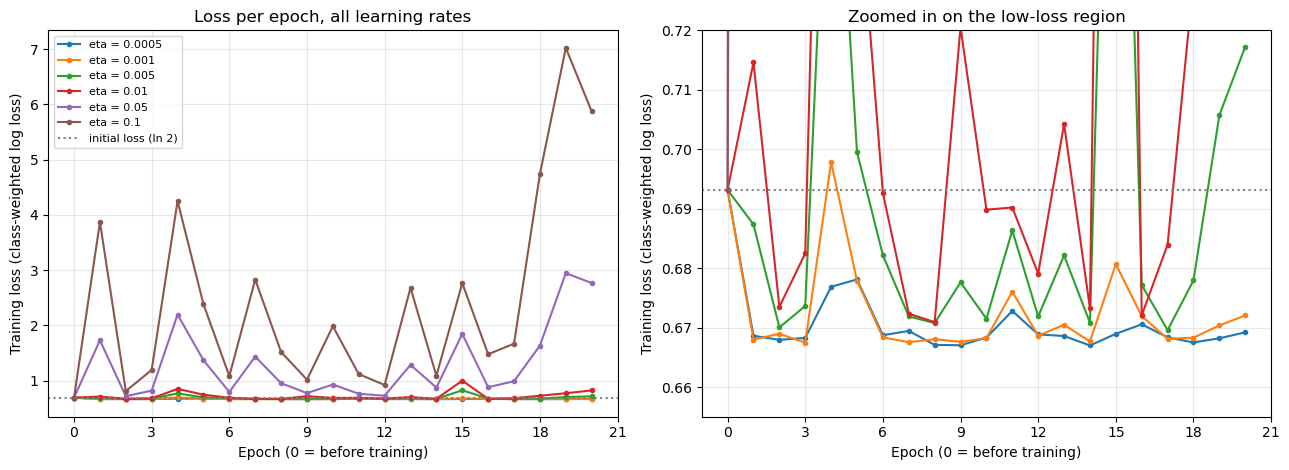

In [23]:
# in loss decay theo một vài giá trị eta
from matplotlib.ticker import MaxNLocator
ETAS = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]
histories = {}
for eta in ETAS:
    print(f"Training with eta = {eta} ...")
    model = LogisticRegressionScratch(eta=eta, max_iter=20, tol=0,
                                      class_weight="balanced")
    model.fit(X_train_np, y_train)
    histories[eta] = model.loss_history
 
initial_loss = next(iter(histories.values()))[0]

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.8))
 
for ax in (ax_full, ax_zoom):
    for eta, h in histories.items():
        ax.plot(range(len(h)), h, marker="o", markersize=3, label=f"eta = {eta}")
    ax.axhline(initial_loss, color="gray", linestyle=":", label="initial loss (ln 2)")
    ax.set_xlabel("Epoch (0 = before training)")
    ax.set_ylabel("Training loss (class-weighted log loss)")
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
 
ax_full.set_title("Loss per epoch, all learning rates")
ax_full.legend(fontsize=8)
 
ax_zoom.set_ylim(0.655, 0.72)
ax_zoom.set_title("Zoomed in on the low-loss region")
 
plt.tight_layout()
plt.show()

In [33]:
# Sklearn model
from sklearn.linear_model import LogisticRegression
sk_model = LogisticRegression(C=1e6, class_weight="balanced", max_iter=100) # C=1e6 để loại L2 regularization
sk_model.fit(X_train_np, y_train)
sk_prob = sk_model.predict_proba(X_test_np)[:, 1]

print(pd.DataFrame([evaluate("sk_model", y_test, sk_prob)]))
print(f"Confusion matrix of Logistic Regression from sklearn:\n  1       0\n{confusion_matrix(y_test, (sk_prob >= 0.5).astype(int))}")

      model  accuracy  precision    recall        f1
0  sk_model   0.57538   0.297633  0.618366  0.401848
Confusion matrix of Logistic Regression from sklearn:
  1       0
[[21247 16526]
 [ 4322  7003]]
